# Diagramas de corpo livre: identificando as forças
### Dinâmica, forças e movimento

**Objetivo:** identificar as forças que agem em um corpo, desenhar seu diagrama de corpo livre e usar a segunda lei de Newton em uma superfície horizontal e em um plano inclinado.

### Como usar este notebook

1. Leia as explicações e tente prever os resultados antes de executar as células.
2. Execute as células de código em ordem, de cima para baixo. Elas fazem as contas e desenham os diagramas.
3. Tente os exercícios sem consultar o gabarito; depois abra-o para conferir seu raciocínio.

**Pré-requisitos:** noções de força, massa e vetores. No exemplo do plano inclinado usamos seno e cosseno; os valores necessários são informados. As visualizações precisam de **Python 3**, **NumPy** e **Matplotlib**, que costumam estar disponíveis no Google Colab. Em um Jupyter local, se necessário, instale-os com `pip install numpy matplotlib`.

## 1. Conceito principal

Um **diagrama de corpo livre** representa um único corpo isolado e mostra, por meio de setas, as **forças que outros corpos exercem sobre ele**. A direção e o sentido de cada seta importam tanto quanto seu módulo (intensidade).

| Força | Como identificá-la |
|---|---|
| **Peso** $\vec P$ | Ação gravitacional da Terra sobre o corpo. Perto da superfície terrestre, seu módulo é $P=mg$ e aponta verticalmente para baixo. |
| **Normal** $\vec N$ | Força de contato perpendicular à superfície, dirigida para fora dela. Seu módulo depende da situação; nem sempre é igual a $mg$. |
| **Força aplicada** $\vec F$ | Um empurrão ou puxão exercido sobre o corpo, na direção informada no problema. |
| **Atrito** $\vec f$ | Força paralela à superfície. O atrito cinético se opõe ao deslizamento relativo entre as superfícies. |

Para um corpo de massa $m$, a **segunda lei de Newton** relaciona a soma vetorial das forças à aceleração:

$$
\boxed{\sum\vec F=m\vec a}
$$

No Sistema Internacional, força é medida em newtons: $1\,\mathrm N=1\,\mathrm{kg\,m/s^2}$. Se a resultante for zero, a aceleração será zero: o corpo pode estar **em repouso ou em movimento com velocidade constante**.

> **Atrito:** no modelo usado aqui, quando há deslizamento, o módulo do atrito cinético é $f_c=\mu_cN$. Sem deslizamento, pode atuar atrito estático, que se ajusta até o limite $f_e\leq\mu_eN$; não devemos usar automaticamente $f_c=\mu_cN$ para um corpo parado em relação à superfície.

## 2. Como montar um diagrama

1. **Escolha e isole o corpo** que será estudado; represente-o por um ponto ou um bloco.
2. Pergunte quais outros corpos interagem com ele e desenhe apenas as forças **sobre o corpo escolhido**. Velocidade e aceleração não são forças.
3. Escolha os eixos positivos. No plano inclinado, é útil escolher um eixo paralelo e outro perpendicular à superfície.
4. Projete as forças nos eixos e aplique $\sum F_x=ma_x$ e $\sum F_y=ma_y$.
5. Confira sentidos, sinais, unidades e hipóteses do problema.

Uma componente é uma **parte de uma força**, não uma força adicional. Se decompor o peso em duas componentes, não some o peso inteiro de novo junto delas no mesmo eixo.

## 3. Exemplo resolvido: bloco deslizando no chão

Um bloco de $5\,\mathrm{kg}$ **já desliza para a direita** em uma superfície horizontal. Uma força horizontal de $20\,\mathrm N$ aponta para a direita. O coeficiente de atrito cinético é $\mu_c=0{,}20$ e $g=10\,\mathrm{m/s^2}$. Não há aceleração vertical nem outras forças verticais.

**Passo 1 — peso e normal.** Escolhendo $+y$ para cima:

$$
P=mg=5\cdot10=50\,\mathrm N,\qquad
\sum F_y=N-P=0\quad\Rightarrow\quad N=50\,\mathrm N.
$$

**Passo 2 — atrito.** Como o bloco desliza para a direita em relação ao chão, o atrito aponta para a esquerda:

$$
f_c=\mu_cN=0{,}20\cdot50=10\,\mathrm N.
$$

**Passo 3 — resultante e aceleração.** Com $+x$ para a direita:

$$
\sum F_x=20-10=10\,\mathrm N,\qquad
a_x=\frac{10}{5}=\boxed{2\,\mathrm{m/s^2}}.
$$

A aceleração aponta para a direita. Vamos conferir as contas e desenhar **as quatro forças**, não apenas a resultante.

In [1]:
# @title Conferindo o exemplo no plano horizontal
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

g = 10.0                 # m/s²
massa_1 = 5.0            # kg
forca_aplicada_1 = 20.0  # N, para a direita
mu_cinetico_1 = 0.20

peso_1 = massa_1 * g
normal_1 = peso_1  # Não há aceleração vertical nem outras forças verticais.
atrito_1 = mu_cinetico_1 * normal_1
resultante_x_1 = forca_aplicada_1 - atrito_1
aceleracao_x_1 = resultante_x_1 / massa_1

print(f"Peso:                 {peso_1:6.2f} N (para baixo)")
print(f"Normal:               {normal_1:6.2f} N (para cima)")
print(f"Atrito cinético:      {atrito_1:6.2f} N (para a esquerda)")
print(f"Resultante horizontal:{resultante_x_1:6.2f} N (sinal positivo: direita)")
print(f"Aceleração horizontal:{aceleracao_x_1:6.2f} m/s² (sinal positivo: direita)")

Peso:                  50.00 N (para baixo)
Normal:                50.00 N (para cima)
Atrito cinético:       10.00 N (para a esquerda)
Resultante horizontal: 10.00 N (sinal positivo: direita)
Aceleração horizontal:  2.00 m/s² (sinal positivo: direita)


### Visualização: diagrama de corpo livre

O ponto preto representa o bloco isolado. Neste desenho, os comprimentos das setas são proporcionais aos módulos das forças; compare também seus sentidos. Os eixos escolhidos são $+x$ para a direita e $+y$ para cima.

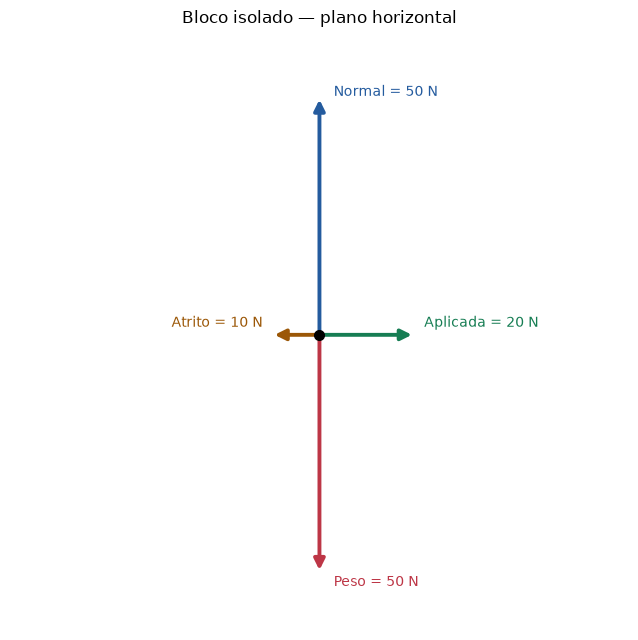

In [2]:
# @title Diagrama de forças no plano horizontal
CORES = {
    "peso": "#bd3646",
    "normal": "#245b9e",
    "aplicada": "#167d53",
    "atrito": "#9b5707",
}

def desenhar_seta(eixo, ponta, cor, estilo="-"):
    '''Desenha uma força ou componente a partir do corpo isolado.'''
    eixo.annotate(
        "", xy=ponta, xytext=(0, 0),
        arrowprops={"arrowstyle": "-|>", "color": cor, "lw": 2.8,
                    "mutation_scale": 16, "linestyle": estilo},
    )

def mostrar_figura(figura, descricao):
    # A descrição acompanha a imagem para uso por leitores de tela.
    display(figura, metadata={"image/png": {"alt": descricao}})
    plt.close(figura)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
desenhar_seta(ax, (0, -peso_1), CORES["peso"])
desenhar_seta(ax, (0, normal_1), CORES["normal"])
desenhar_seta(ax, (forca_aplicada_1, 0), CORES["aplicada"])
desenhar_seta(ax, (-atrito_1, 0), CORES["atrito"])
ax.plot(0, 0, "ko", markersize=7, zorder=5)

ax.text(3, normal_1 + 1, f"Normal = {normal_1:.0f} N", color=CORES["normal"], va="center")
ax.text(3, -peso_1 - 2, f"Peso = {peso_1:.0f} N", color=CORES["peso"], va="center")
ax.text(forca_aplicada_1 + 2, 2.5, f"Aplicada = {forca_aplicada_1:.0f} N",
        color=CORES["aplicada"], va="center")
ax.text(-atrito_1 - 2, 2.5, f"Atrito = {atrito_1:.0f} N",
        color=CORES["atrito"], ha="right", va="center")

ax.set_xlim(-65, 65)
ax.set_ylim(-62, 62)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Bloco isolado — plano horizontal", pad=12)
fig.tight_layout()
mostrar_figura(fig, "Diagrama de forças em um bloco: peso para baixo, normal para cima, "
               "força aplicada para a direita e, quando presente, atrito para a esquerda. "
               "Os comprimentos das setas representam os módulos indicados.")

## 4. Exemplo resolvido: plano inclinado

Agora um bloco de $2\,\mathrm{kg}$ **já desliza para baixo** em um plano de $30^\circ$. Use $g=10\,\mathrm{m/s^2}$ e suponha que o bloco permaneça em contato com a superfície, sem aceleração perpendicular a ela. Primeiro, imagine o plano sem atrito; depois, considere $\mu_c=0{,}20$.

Escolhemos $+x$ **para baixo do plano** e $+y$ **para fora da superfície**. O peso continua vertical: suas componentes têm módulos

$$
P_{\parallel}=mg\sin\theta,\qquad P_{\perp}=mg\cos\theta.
$$

Para $\theta=30^\circ$, $\sin30^\circ=0{,}5$ e $\cos30^\circ\approx0{,}866$. Assim:

$$
P=20\,\mathrm N,\qquad P_{\parallel}=10\,\mathrm N,\qquad
P_{\perp}\approx17{,}32\,\mathrm N.
$$

A componente perpendicular do peso aponta **para dentro** do plano. Como não há aceleração perpendicular nem outras forças nessa direção, $N=P_{\perp}\approx17{,}32\,\mathrm N$. Note que aqui $N\ne mg$.

- **Sem atrito:** $\sum F_x=10\,\mathrm N$ e $a_x=10/2=5\,\mathrm{m/s^2}$.
- **Com atrito cinético:** o atrito aponta para cima do plano, contra o deslizamento. Seu módulo é $f_c=0{,}20\cdot17{,}32\approx3{,}46\,\mathrm N$. Logo, $\sum F_x\approx10-3{,}46=6{,}54\,\mathrm N$ e $a_x\approx3{,}27\,\mathrm{m/s^2}$, para baixo do plano.

In [3]:
# @title Comparando o plano inclinado sem e com atrito
massa_2 = 2.0           # kg
angulo_graus = 30.0     # ângulo do plano com a horizontal
mu_cinetico_2 = 0.20    # válido enquanto o bloco desliza
theta = np.deg2rad(angulo_graus)

peso_2 = massa_2 * g
peso_paralelo_2 = peso_2 * np.sin(theta)
peso_perpendicular_2 = peso_2 * np.cos(theta)
normal_2 = peso_perpendicular_2
atrito_2 = mu_cinetico_2 * normal_2
aceleracao_sem_atrito = peso_paralelo_2 / massa_2
aceleracao_com_atrito = (peso_paralelo_2 - atrito_2) / massa_2

print(f"Peso:                         {peso_2:6.2f} N")
print(f"Componente paralela do peso:  {peso_paralelo_2:6.2f} N (descida)")
print(f"Normal:                       {normal_2:6.2f} N (para fora do plano)")
print(f"Atrito cinético:              {atrito_2:6.2f} N (subida)")
print(f"Aceleração sem atrito:        {aceleracao_sem_atrito:6.2f} m/s²")
print(f"Aceleração com atrito:        {aceleracao_com_atrito:6.2f} m/s²")
print("O sentido positivo das acelerações é para baixo do plano.")

Peso:                          20.00 N
Componente paralela do peso:   10.00 N (descida)
Normal:                        17.32 N (para fora do plano)
Atrito cinético:                3.46 N (subida)
Aceleração sem atrito:          5.00 m/s²
Aceleração com atrito:          3.27 m/s²
O sentido positivo das acelerações é para baixo do plano.


### Visualização: forças e componentes no plano inclinado

À esquerda, o diagrama mostra as **três forças reais** no caso com atrito: peso, normal e atrito. À direita, o peso é decomposto nas direções paralela e perpendicular ao plano. As componentes tracejadas substituem o peso na decomposição; **não são forças extras**. As linhas cinzas indicam a direção da superfície.

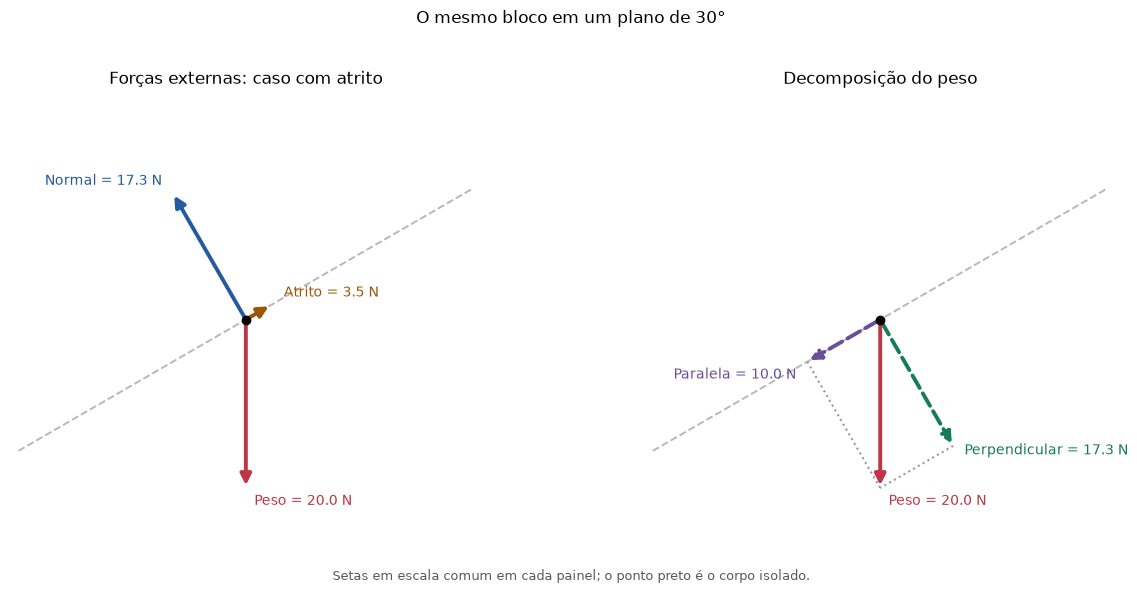

In [4]:
# @title Diagrama e decomposição do peso no plano inclinado
# No desenho, o plano sobe para a direita. +x aponta na descida e +y para fora.
eixo_x = np.array([-np.cos(theta), -np.sin(theta)])
eixo_y = np.array([-np.sin(theta),  np.cos(theta)])
vetor_peso = np.array([0.0, -peso_2])
vetor_normal = normal_2 * eixo_y
vetor_atrito = -atrito_2 * eixo_x
vetor_peso_paralelo = peso_paralelo_2 * eixo_x
vetor_peso_perpendicular = -peso_perpendicular_2 * eixo_y

fig, (ax_forcas, ax_componentes) = plt.subplots(1, 2, figsize=(13, 6))
for ax in (ax_forcas, ax_componentes):
    linha_x = np.array([-27.0, 27.0])
    ax.plot(linha_x, np.tan(theta) * linha_x, "--", color="0.72", lw=1.4)
    ax.plot(0, 0, "ko", markersize=6, zorder=5)
    ax.set_xlim(-28, 28)
    ax.set_ylim(-27, 27)
    ax.set_aspect("equal")
    ax.axis("off")

desenhar_seta(ax_forcas, vetor_peso, CORES["peso"])
desenhar_seta(ax_forcas, vetor_normal, CORES["normal"])
desenhar_seta(ax_forcas, vetor_atrito, CORES["atrito"])
ax_forcas.text(1, -22, f"Peso = {peso_2:.1f} N", color=CORES["peso"])
ax_forcas.text(-10, 16, f"Normal = {normal_2:.1f} N",
               color=CORES["normal"], ha="right")
ax_forcas.text(vetor_atrito[0] + 1.5, vetor_atrito[1] + 1.0,
               f"Atrito = {atrito_2:.1f} N", color=CORES["atrito"])
ax_forcas.set_title("Forças externas: caso com atrito")

desenhar_seta(ax_componentes, vetor_peso, CORES["peso"])
desenhar_seta(ax_componentes, vetor_peso_paralelo, "#6b4d9a", "--")
desenhar_seta(ax_componentes, vetor_peso_perpendicular, "#167d53", "--")
# As linhas pontilhadas completam o paralelogramo da soma das componentes.
ax_componentes.plot([vetor_peso_paralelo[0], vetor_peso[0]],
                     [vetor_peso_paralelo[1], vetor_peso[1]], ":", color="0.6")
ax_componentes.plot([vetor_peso_perpendicular[0], vetor_peso[0]],
                     [vetor_peso_perpendicular[1], vetor_peso[1]], ":", color="0.6")
ax_componentes.text(1, -22, f"Peso = {peso_2:.1f} N", color=CORES["peso"])
ax_componentes.text(-10, -7, f"Paralela = {peso_paralelo_2:.1f} N",
                    color="#6b4d9a", ha="right")
ax_componentes.text(10, -16, f"Perpendicular = {peso_perpendicular_2:.1f} N",
                    color="#167d53")
ax_componentes.set_title("Decomposição do peso")

fig.suptitle(f"O mesmo bloco em um plano de {angulo_graus:g}°", y=0.98)
fig.text(0.5, 0.03, "Setas em escala comum em cada painel; o ponto preto é o corpo isolado.",
         ha="center", fontsize=9, color="0.35")
fig.tight_layout(rect=(0, 0.06, 1, 0.94))
mostrar_figura(fig, "Dois diagramas de um plano inclinado. No primeiro, o peso aponta "
               "para baixo, a normal para fora do plano e, quando há atrito, este aponta "
               "para cima da rampa. No segundo, o peso é decomposto em uma parte para "
               "baixo da rampa e outra para dentro da superfície.")

### Experimente: como o ângulo muda a aceleração?

O gráfico mantém o mesmo $g$ e o mesmo coeficiente de atrito do exemplo, enquanto varia o ângulo do plano. **Antes de executar:** preveja se a aceleração com atrito será maior ou menor que a aceleração sem atrito.

As duas curvas descrevem um bloco **já deslizando para baixo**. Se a aceleração com atrito for negativa, ela aponta para cima do plano e o bloco está desacelerando enquanto ainda desliza para baixo. O gráfico não prevê o que acontece depois que ele para: nessa situação é preciso analisar o atrito estático.

**Atividade:** compare as duas curvas em $30^\circ$. Depois, altere `mu_cinetico_2` de `0.20` para `0.40` na célula do exemplo inclinado, execute novamente essa célula e as seguintes, e explique o que mudou. As contas do texto acima descrevem o valor original, $0{,}20$.

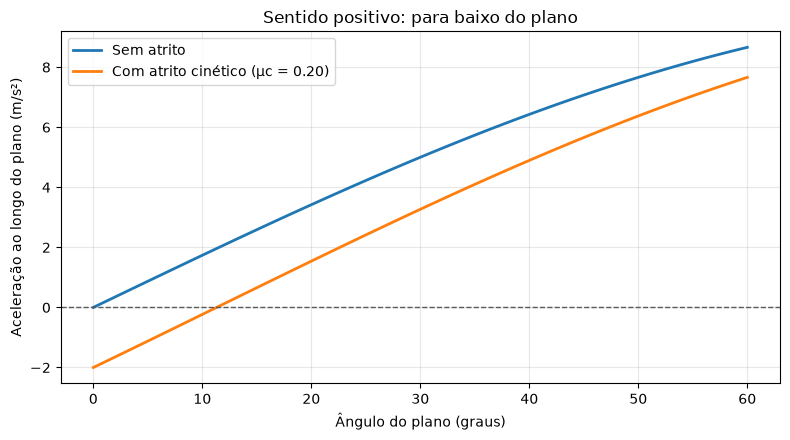

In [5]:
# @title Aceleração em função do ângulo, durante a descida
angulos = np.linspace(0, 60, 121)  # graus
angulos_rad = np.deg2rad(angulos)
aceleracoes_sem_atrito = g * np.sin(angulos_rad)
aceleracoes_com_atrito = g * (np.sin(angulos_rad) - mu_cinetico_2 * np.cos(angulos_rad))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(angulos, aceleracoes_sem_atrito, lw=2, label="Sem atrito")
ax.plot(angulos, aceleracoes_com_atrito, lw=2,
        label=f"Com atrito cinético (μc = {mu_cinetico_2:.2f})")
ax.axhline(0, color="0.35", lw=1, linestyle="--")
ax.set_xlabel("Ângulo do plano (graus)")
ax.set_ylabel("Aceleração ao longo do plano (m/s²)")
ax.set_title("Sentido positivo: para baixo do plano")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
mostrar_figura(fig, "Gráfico da aceleração durante a descida em função do ângulo do plano. "
               "Há uma curva sem atrito e outra com atrito cinético; para coeficiente "
               "positivo, a segunda fica abaixo da primeira e pode ser negativa "
               "em ângulos pequenos.")

## 5. Ligação com trabalho e energia

Volte ao bloco do exemplo horizontal. Se ele se desloca $3\,\mathrm m$ para a direita enquanto as forças permanecem constantes, a força aplicada e o atrito realizam trabalhos de sinais opostos:

$$
W_F=20\cdot3=+60\,\mathrm J,\qquad
W_{\text{atrito}}=-10\cdot3=-30\,\mathrm J.
$$

O peso e a normal são perpendiculares ao deslocamento horizontal, então seus trabalhos são zero. O trabalho resultante é $+30\,\mathrm J$: pelo teorema trabalho–energia, esse é o aumento da energia cinética do bloco durante o deslocamento.

In [6]:
# @title Conferindo o trabalho das forças do exemplo horizontal
deslocamento_1 = 3.0  # m, para a direita
trabalho_aplicada = forca_aplicada_1 * deslocamento_1
trabalho_atrito = -atrito_1 * deslocamento_1
trabalho_resultante = trabalho_aplicada + trabalho_atrito  # peso e normal: zero

print(f"Trabalho da força aplicada: {trabalho_aplicada:+.1f} J")
print(f"Trabalho do atrito:         {trabalho_atrito:+.1f} J")
print(f"Trabalho resultante:        {trabalho_resultante:+.1f} J")
print(f"Variação da energia cinética: {trabalho_resultante:+.1f} J")

Trabalho da força aplicada: +60.0 J
Trabalho do atrito:         -30.0 J
Trabalho resultante:        +30.0 J
Variação da energia cinética: +30.0 J


## 6. Exercícios de fixação

Tente desenhar cada diagrama e resolver no papel antes de abrir o gabarito. Considere $g=10\,\mathrm{m/s^2}$.

**1. Bloco no chão.** Um bloco de $4\,\mathrm{kg}$ já desliza para a direita. Uma força horizontal de $25\,\mathrm N$ o empurra para a direita e o coeficiente de atrito cinético é $0{,}25$. Não há aceleração vertical nem outras forças verticais.

a. Desenhe as quatro forças e determine seus módulos.  
b. Calcule a resultante horizontal e a aceleração.  
c. Se o bloco se deslocar $4\,\mathrm m$ para a direita sob essas forças constantes, calcule o trabalho da força aplicada, do atrito e da resultante.

**2. Plano inclinado.** Um bloco de $2\,\mathrm{kg}$ já desliza para baixo de um plano de $45^\circ$, com $\mu_c=0{,}50$. Ele permanece em contato com o plano, sem aceleração perpendicular; não há outras forças além de peso, normal e atrito. Use $\sin45^\circ=\cos45^\circ\approx0{,}707$.

a. Qual é o módulo da normal? E do atrito cinético?  
b. Qual é a aceleração ao longo do plano e qual é seu sentido?

**3. Perguntas conceituais.**

a. Uma resultante nula exige que o corpo esteja parado?  
b. Peso e normal formam um par de ação e reação entre si?  
c. Se o bloco do exemplo inclinado parar em relação ao plano, podemos continuar usando automaticamente $f_c=\mu_cN$?

<details>
<summary><strong>Abrir o gabarito comentado</strong></summary>

**1. Bloco no chão.**

- $P=4\cdot10=40\,\mathrm N$ para baixo e $N=40\,\mathrm N$ para cima.
- Força aplicada: $25\,\mathrm N$ para a direita. Atrito: $f_c=0{,}25\cdot40=10\,\mathrm N$ para a esquerda.
- $\sum F_x=25-10=15\,\mathrm N$ e $a_x=15/4=\boxed{3{,}75\,\mathrm{m/s^2}}$ para a direita.
- $W_F=25\cdot4=+100\,\mathrm J$; $W_{\text{atrito}}=-10\cdot4=-40\,\mathrm J$; $W_{\text{resultante}}=\boxed{+60\,\mathrm J}$. Peso e normal não realizam trabalho no deslocamento horizontal.

**2. Plano inclinado.**

- $P=20\,\mathrm N$; $N=mg\cos45^\circ\approx14{,}14\,\mathrm N$.
- $f_c=0{,}50N\approx7{,}07\,\mathrm N$, apontando para cima do plano.
- $P_{\parallel}=mg\sin45^\circ\approx14{,}14\,\mathrm N$. Assim, a resultante na descida é aproximadamente $14{,}14-7{,}07=7{,}07\,\mathrm N$ e $a\approx\boxed{3{,}54\,\mathrm{m/s^2}}$ para baixo do plano.

**3. Perguntas conceituais.**

a. Não. Resultante nula significa aceleração nula: o corpo também pode ter velocidade constante diferente de zero.  
b. Não. Peso e normal agem **no mesmo corpo**; as forças de um par de ação e reação agem em corpos diferentes.  
c. Não. Se não há deslizamento relativo, pode atuar atrito estático; é preciso verificar seu valor e limite para a nova situação.

</details>

## 7. Resumo e próximos passos

- Isole um corpo e desenhe somente as forças **sobre ele**.
- A resultante determina a aceleração: $\sum\vec F=m\vec a$. Resultante zero não exige velocidade zero.
- A normal é perpendicular à superfície; $N=mg$ apenas em situações com as hipóteses adequadas, como no exemplo horizontal.
- Enquanto há deslizamento, o atrito cinético se opõe ao movimento **relativo entre as superfícies** e, neste modelo, $f_c=\mu_cN$.
- Em um plano inclinado, decomponha o peso sem tratá-lo e suas componentes como forças independentes.

Para continuar no acervo:

1. [Trabalho de uma força constante](../trabalho/forca_constante/04_trabalho_forca_constante.ipynb).
2. [Trabalho da força de atrito](../trabalho/atrito/02_trabalho_atrito_resistente.ipynb).
3. [Teorema do trabalho e energia cinética](../trabalho/teorema_trabalho_energia/01_teorema_trabalho_energia.ipynb).